# 18 Model family per cutoff, and seed stability

Notebook 16 suggested that Huber is better at 09:00 (where it uses demand to rank) and gradient boosting (GBM) at 07:00, but the pooled differences were small compared with the single-seed noise. Two questions, both on the structure of D-008 (`forecast = ref28 + L(D) + centred V0 deviation`, split models, 07:00 without demand):

1. **How stable is the GBM across random seeds?** Seeds 0-4 of the same model. (The settings use no early stopping and no feature sub-sampling, so the seed may change nothing; this checks that.)
2. **Which family, or which blend, at each cutoff?** Fixed before running: Huber; GBM (seed 0, as before); GBM averaged over the five seeds; and the equal-weight average of Huber and GBM (seed 0), and of Huber and the seed-averaged GBM. Because Huber and GBM share the reference `ref28` and the level `L(D)`, the average of their forecasts is `ref28 + L(D) +` the average of their centred deviations, i.e. an average of the two models' within-day shapes.

Same 17 folds, same scored rows, dev-only. Metrics as in notebook 16 (differences to the 28-day baseline at the same cutoff; all folds, folds 0-12, late folds 13-16), plus paired differences between the variants.

## Init

In [1]:
import sys, time
sys.path[:0] = ["notebooks", "."]  # _common imports from repo root or notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import HuberRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from _eval import make_folds, score

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100})

TT = pd.read_parquet("outputs/feature_table_dev.parquet").reset_index(drop=True)
REF = "med28_same"
days = pd.DatetimeIndex(sorted(TT["day"].unique()))
folds = make_folds(days, 28, 17, 1)
val_days_all = pd.DatetimeIndex(np.concatenate([f["val_days"].values for f in folds]))
COMMON = TT[REF].notna() & TT["price"].notna()
TT["ydev"] = TT["price"] - TT[REF]
CUT = {7: TT["cutoff_hour"] == 7, 9: TT["cutoff_hour"] == 9}

ABS = ["demand_mw", "wind_mw", "emb_wind_mw", "emb_solar_mw"]
ANOM = ["demand_anom", "wind_anom", "emb_wind_anom", "emb_solar_anom"]
HIST = ["med28_same", "med7_same", "d2_same", "level24h", "level7", "level28", "level_gap"]
MGN = ["mgn_min_demand", "mgn_surplus", "mgn_constrained", "mgn_gen_avail", "mgn_ic_import"]
GBM_EXTRA = ["wind_total_mw", "demand_age_h", "wind_age_h", "emb_age_h", "demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev", "is_weekend"]
DEMAND_COLS = {"demand_mw", "demand_age_h", "demand_rev", "demand_anom"}
REV_COLS = {"demand_rev", "wind_rev", "emb_wind_rev", "emb_solar_rev"}
DROP = {9: set(), 7: DEMAND_COLS | REV_COLS}
GCOLS = {c: [x for x in dict.fromkeys(["hour_frac", "weekday", "bank_holiday", "doy_sin", "doy_cos", "clock_change_day"] + ABS + MGN + GBM_EXTRA + HIST) if x not in DROP[c]] for c in (7, 9)}
LCOLS = {9: ANOM + ["is_weekend", "bank_holiday"], 7: [a for a in ANOM if a != "demand_anom"] + ["is_weekend", "bank_holiday"]}

dm = TT[COMMON & CUT[9]].groupby("day")["ydev"].agg(["mean", "count"])
DAILY = {}
for c in (7, 9):
    g = TT[CUT[c]].groupby("day")
    d = g[ANOM].mean(); d["is_weekend"] = g["is_weekend"].mean(); d["bank_holiday"] = g["bank_holiday"].mean()
    d["target"] = dm["mean"].where(dm["count"] >= 40).reindex(d.index)
    DAILY[c] = d

def gbm(seed):
    return HistGradientBoostingRegressor(loss="absolute_error", max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=100, l2_regularization=1.0, early_stopping=False, random_state=seed)
def level_model():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), HuberRegressor(alpha=10, epsilon=1.35, max_iter=300))

def fold_table(pred, cut):
    rows = []
    for f in folds:
        d = TT[CUT[cut] & COMMON & TT["day"].isin(f["val_days"])].assign(pred=pred)
        s = score(d, "pred"); s["fold"] = f["fold"]; rows.append(s)
    return pd.DataFrame(rows).set_index("fold")
BASE = {c: fold_table(TT[REF], c) for c in (7, 9)}
print("ready; baseline MAE", {c: round(BASE[c]["MAE"].mean(), 3) for c in BASE})

ready; baseline MAE {7: np.float64(30.2), 9: np.float64(30.2)}


## 1. GBM with seeds 0-4

Each run gives the forecast `ref28 + L(D) + centred GBM deviation` for one seed. Seed 0 must reproduce notebook 16 exactly (check below).

In [2]:
def run_gbm(cut, seed):
    cols = GCOLS[cut]; lc = LCOLS[cut]
    dev0 = pd.Series(np.nan, index=TT.index); lvl = pd.Series(np.nan, index=DAILY[cut].index)
    for f in folds:
        tr = TT[CUT[cut] & TT["day"].isin(f["train_days"]) & COMMON]
        va = TT[CUT[cut] & TT["day"].isin(f["val_days"])]
        dev0.loc[va.index] = gbm(seed).fit(tr[cols], tr["ydev"]).predict(va[cols])
        dtr = DAILY[cut].loc[DAILY[cut].index.isin(f["train_days"]) & DAILY[cut]["target"].notna()]
        lm = level_model().fit(dtr[lc], dtr["target"])
        dva = DAILY[cut].loc[DAILY[cut].index.isin(f["val_days"])]
        lvl.loc[dva.index] = lm.predict(dva[lc])
    d0c = dev0 - dev0.groupby(TT["day"]).transform("mean")
    return d0c.where(CUT[cut]), TT["day"].map(lvl).where(CUT[cut])          # centred deviation, level

SEEDS = [0, 1, 2, 3, 4]
C, L = {}, {}
t0 = time.time()
for cut in (9, 7):
    for s in SEEDS:
        C[(cut, s)], L[(cut, s)] = run_gbm(cut, s)
    print("cutoff", cut, f"{time.time() - t0:.0f}s")

P16 = pd.read_parquet("outputs/cv_preds_cutoffs_0700_0900.parquet")
PT = TT[["period_start", "cutoff_hour"]].merge(P16, on=["period_start", "cutoff_hour"], how="left"); PT.index = TT.index
NAME = {9: "split 09", 7: "split 07"}
for cut in (9, 7):
    mine = (TT[REF] + L[(cut, 0)] + C[(cut, 0)]).where(CUT[cut])
    ref16 = PT[f"gbm | {NAME[cut]} | {cut} | + level"].where(CUT[cut])
    both = mine.notna() & ref16.notna()
    print(cut, "seed 0 vs notebook 16, max abs difference:", float((mine[both] - ref16[both]).abs().max()))

cutoff 9 71s


cutoff 7 136s
9 seed 0 vs notebook 16, max abs difference: 0.0
7 seed 0 vs notebook 16, max abs difference: 0.0


## 2. Seed stability

Pooled over the 17 folds: the per-seed forecasts, differences to the baseline, and the largest difference between seeds in the predictions themselves.

In [3]:
def row(cut, pred):
    ft = fold_table(pred, cut); b = BASE[cut]
    d = {m: ft[m] - b[m] for m in ["MAE", "RMSE", "hit_top8", "hit_bot8", "MAE_top10", "MAE_bot10"]}
    return ft, {"dMAE all": d["MAE"].mean(), "dMAE late": d["MAE"].loc[13:].mean(), "dRMSE all": d["RMSE"].mean(),
                "dHitTop": d["hit_top8"].mean(), "dHitBot": d["hit_bot8"].mean(), "dTop10": d["MAE_top10"].mean(), "dBot10": d["MAE_bot10"].mean(),
                "bias late": ft["bias"].loc[13:].mean()}
for cut in (9, 7):
    rows = {f"seed {s}": row(cut, TT[REF] + L[(cut, s)] + C[(cut, s)])[1] for s in SEEDS}
    R = pd.DataFrame(rows).T
    print(f"{cut:02d}:00")
    print(R.round(4).to_string())
    print("range over seeds:", (R.max() - R.min()).round(4).to_dict())
    ok = CUT[cut] & COMMON
    print("max |difference in predictions| between seed 0 and seeds 1-4:", [round(float((C[(cut, 0)][ok] - C[(cut, s)][ok]).abs().max()), 4) for s in SEEDS[1:]])
    print()

09:00
        dMAE all  dMAE late  dRMSE all  dHitTop  dHitBot  dTop10   dBot10  bias late
seed 0    -2.029    -1.5859      -4.07   0.0236   0.0334 -4.9296 -23.2487    -2.1848
seed 1    -2.029    -1.5859      -4.07   0.0236   0.0334 -4.9296 -23.2487    -2.1848
seed 2    -2.029    -1.5859      -4.07   0.0236   0.0334 -4.9296 -23.2487    -2.1848
seed 3    -2.029    -1.5859      -4.07   0.0236   0.0334 -4.9296 -23.2487    -2.1848
seed 4    -2.029    -1.5859      -4.07   0.0236   0.0334 -4.9296 -23.2487    -2.1848
range over seeds: {'dMAE all': 0.0, 'dMAE late': 0.0, 'dRMSE all': 0.0, 'dHitTop': 0.0, 'dHitBot': 0.0, 'dTop10': 0.0, 'dBot10': 0.0, 'bias late': 0.0}
max |difference in predictions| between seed 0 and seeds 1-4: [0.0, 0.0, 0.0, 0.0]



07:00
        dMAE all  dMAE late  dRMSE all  dHitTop  dHitBot  dTop10   dBot10  bias late
seed 0   -1.7495    -1.2712    -3.5792   0.0181   0.0286 -3.8476 -20.6232    -1.5842
seed 1   -1.7495    -1.2712    -3.5792   0.0181   0.0286 -3.8476 -20.6232    -1.5842
seed 2   -1.7495    -1.2712    -3.5792   0.0181   0.0286 -3.8476 -20.6232    -1.5842
seed 3   -1.7495    -1.2712    -3.5792   0.0181   0.0286 -3.8476 -20.6232    -1.5842
seed 4   -1.7495    -1.2712    -3.5792   0.0181   0.0286 -3.8476 -20.6232    -1.5842
range over seeds: {'dMAE all': 0.0, 'dMAE late': 0.0, 'dRMSE all': 0.0, 'dHitTop': 0.0, 'dHitBot': 0.0, 'dTop10': 0.0, 'dBot10': 0.0, 'bias late': 0.0}
max |difference in predictions| between seed 0 and seeds 1-4: [0.0, 0.0, 0.0, 0.0]



## 3. Family and blend per cutoff

In [4]:
FT, PR = {}, {}
for cut in (9, 7):
    hub = PT[f"huber | {NAME[cut]} | {cut} | + level"].where(CUT[cut])
    g0 = TT[REF] + L[(cut, 0)] + C[(cut, 0)]
    g5 = TT[REF] + L[(cut, 0)] + sum(C[(cut, s)] for s in SEEDS) / len(SEEDS)
    PR[(cut, "Huber")] = hub
    PR[(cut, "GBM seed 0")] = g0
    PR[(cut, "GBM 5 seeds")] = g5
    PR[(cut, "avg Huber + GBM seed 0")] = 0.5 * (hub + g0)
    PR[(cut, "avg Huber + GBM 5 seeds")] = 0.5 * (hub + g5)
rows = {}
for (cut, name), p in PR.items():
    ft, r = row(cut, p.where(CUT[cut])); FT[(cut, name)] = ft; rows[f"{cut:02d}:00 {name}"] = r
print(pd.DataFrame(rows).T.round(3).to_string())

                               dMAE all  dMAE late  dRMSE all  dHitTop  dHitBot  dTop10  dBot10  bias late
09:00 Huber                      -2.059     -1.501     -4.300    0.032    0.049  -4.111 -19.882     -2.185
09:00 GBM seed 0                 -2.029     -1.586     -4.070    0.024    0.033  -4.930 -23.249     -2.185
09:00 GBM 5 seeds                -2.029     -1.586     -4.070    0.024    0.033  -4.930 -23.249     -2.185
09:00 avg Huber + GBM seed 0     -2.231     -1.803     -4.464    0.033    0.046  -4.611 -21.638     -2.185
09:00 avg Huber + GBM 5 seeds    -2.231     -1.803     -4.464    0.033    0.046  -4.611 -21.638     -2.185
07:00 Huber                      -1.546     -1.277     -3.409    0.011    0.018  -2.040 -15.397     -1.584
07:00 GBM seed 0                 -1.750     -1.271     -3.579    0.018    0.029  -3.848 -20.623     -1.584
07:00 GBM 5 seeds                -1.750     -1.271     -3.579    0.018    0.029  -3.848 -20.623     -1.584
07:00 avg Huber + GBM seed 0     -1.8

## 4. Paired comparisons

Mean per-fold difference +/- standard error over 17 folds (negative better for MAE/RMSE, positive better for hit rates), `late` over folds 13-16, and folds in which the first is better on MAE. Standard errors treat adjacent folds as independent, so they are optimistic.

                                                                 MAE all MAE late          RMSE all RMSE late      hit_top8 all hit_top8 late      hit_bot8 all hit_bot8 late MAE better in
09:00 GBM 5 seeds - GBM seed 0                          +0.000 +/- 0.000   +0.000  +0.000 +/- 0.000    +0.000  +0.000 +/- 0.000        +0.000  +0.000 +/- 0.000        +0.000             0
09:00 GBM seed 0 - Huber                                +0.030 +/- 0.159   -0.085  +0.230 +/- 0.172    -0.115  -0.008 +/- 0.004        -0.001  -0.015 +/- 0.012        -0.013             7
09:00 avg Huber + GBM seed 0 - Huber                    -0.172 +/- 0.085   -0.302  -0.164 +/- 0.087    -0.414  +0.001 +/- 0.003        +0.003  -0.003 +/- 0.005        -0.011            12
09:00 avg Huber + GBM seed 0 - GBM seed 0               -0.202 +/- 0.077   -0.217  -0.394 +/- 0.092    -0.299  +0.009 +/- 0.003        +0.004  +0.013 +/- 0.009        +0.002            11
09:00 avg Huber + GBM 5 seeds - avg Huber + GBM seed 0  +0.0

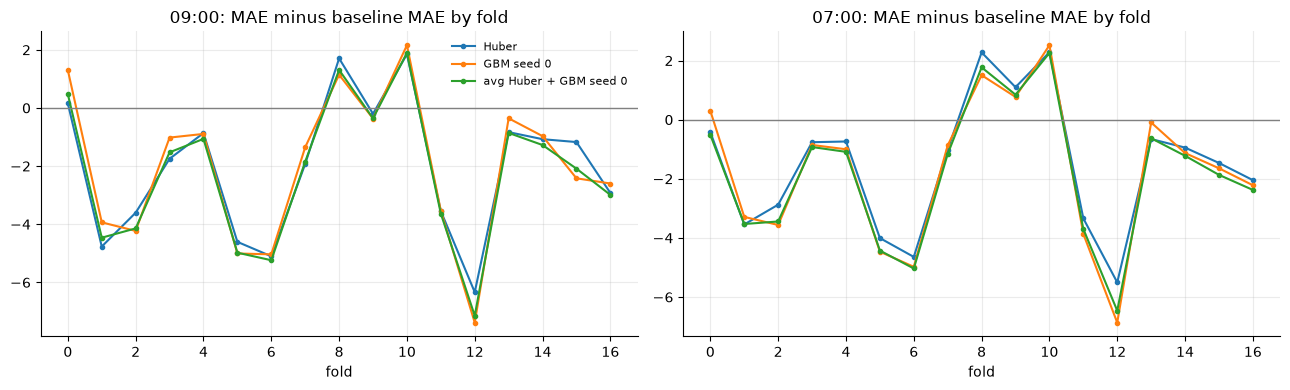

In [5]:
def paired(a, b):
    r = {}
    for m in ["MAE", "RMSE", "hit_top8", "hit_bot8"]:
        d = FT[a][m] - FT[b][m]
        r[f"{m} all"] = f"{d.mean():+.3f} +/- {d.std() / np.sqrt(17):.3f}"; r[f"{m} late"] = f"{d.loc[13:].mean():+.3f}"
    r["MAE better in"] = int(((FT[a]["MAE"] - FT[b]["MAE"]) < 0).sum())
    return r
rows = {}
for cut in (9, 7):
    for a, b in [("GBM 5 seeds", "GBM seed 0"), ("GBM seed 0", "Huber"), ("avg Huber + GBM seed 0", "Huber"), ("avg Huber + GBM seed 0", "GBM seed 0"),
                 ("avg Huber + GBM 5 seeds", "avg Huber + GBM seed 0")]:
        rows[f"{cut:02d}:00 {a} - {b}"] = paired((cut, a), (cut, b))
print(pd.DataFrame(rows).T.to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cut in zip(axes, (9, 7)):
    for name in ["Huber", "GBM seed 0", "avg Huber + GBM seed 0"]:
        ax.plot(FT[(cut, name)]["MAE"] - BASE[cut]["MAE"], marker="o", ms=3, label=name)
    ax.axhline(0, color="grey", lw=1); ax.set_title(f"{cut:02d}:00: MAE minus baseline MAE by fold"); ax.set_xlabel("fold")
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()
out = pd.DataFrame({f"{c} | {n}": p for (c, n), p in PR.items()})
for c in ["day", "period_start", "cutoff_hour", "price", REF]:
    out[c] = TT[c]
out[out["day"].isin(val_days_all)].to_parquet("outputs/cv_preds_families_0700_0900.parquet", index=False)

## Findings (17 folds; variants fixed before running; differences to the 28-day baseline at the same cutoff)

- **The GBM is deterministic here: seeds 0-4 give identical predictions** (maximum difference 0.0 at both cutoffs). With no early stopping and no feature sub-sampling the seed is never used (as noted in notebook 09), so the "single seed" caveat written in notebooks 16 and 17 does not apply to these models and is corrected there. The 5-seed average equals seed 0. The relevant uncertainty is the fold-to-fold standard error.
- **The family difference between the cutoffs is weak.** Huber against GBM (the latter minus the former): at 09:00 MAE +0.03 +/- 0.16 (GBM better in 7 of 17 folds), top-8 hit -0.008 +/- 0.004, bottom-8 -0.015 +/- 0.012; at 07:00 MAE -0.20 +/- 0.12 (12 of 17), hit +0.008 / +0.010. The notebook-16 impression (Huber at 09:00, GBM at 07:00) is a small tendency, within about one to two standard errors.
- **The equal-weight average of Huber and GBM is the best or tied on the headline metrics at both cutoffs.** 09:00: MAE -2.23 (Huber -2.06, GBM -2.03), RMSE -4.46 (-4.30, -4.07), late-fold MAE -1.80 (-1.50, -1.59), hit +0.033 / +0.046 (Huber +0.032 / +0.049, GBM +0.024 / +0.033). Paired: against Huber MAE -0.17 +/- 0.09 (better in 12 of 17 folds), hit +0.001 / -0.003; against GBM MAE -0.20 +/- 0.08 (11 of 17), hit +0.009 / +0.013. 07:00: MAE -1.85 (Huber -1.55, GBM -1.75), RMSE -3.79, late -1.52 (-1.28, -1.27), hit +0.021 / +0.033 (+0.011 / +0.018, +0.018 / +0.029); against Huber MAE -0.31 +/- 0.06 (15 of 17), against GBM -0.10 +/- 0.07 (11 of 17).
- **The decile MAEs favour GBM slightly.** Top-decile MAE gain over the baseline: GBM -4.9, blend -4.6, Huber -4.1 at 09:00 (07:00: -3.8, -3.0, -2.0); bottom decile -23.2, -21.6, -19.9 (07:00: -20.6, -18.1, -15.4). The blend sits between the two families on these, and above the better one on MAE, RMSE and late-fold MAE.
- **Mean error is the same in all variants** (late folds -2.2 at 09:00 and -1.6 at 07:00) because they share `ref28` and `L(D)`; the blend only changes the within-day shape.
- **Reading.** An equal-weight blend of the two families at each cutoff is a reasonable candidate, ahead of choosing one family per cutoff. The gain over the better single family is small (0.1 to 0.3 MAE, 1.5 to 2.5 standard errors), the weights (50/50) were not tuned, and five variants were looked at on these folds, so the advantage is probably somewhat overstated.
- **Caveats.** (1) The structure and the choice among variants were made on these same folds, so the numbers are optimistic (D-008 caveat). (2) Standard errors treat adjacent folds as independent. (3) Late-fold statements rest on four folds. (4) Only two families; other families (e.g. a different loss or a ranking model) are untried. (5) The mean level in the late folds is still too low by about 2 (fold 16 by 6.6-8.4).
